In [16]:
"""
AET Task 3 — Section 5: Mean Blade Angles and Number of Blades
V-22 Osprey Search-and-Rescue Turboshaft Engine

Assumptions:
  - Compressor: axial entry (alpha1=0) to each rotor; stator returns to axial
  - Turbines:   axial exit  (alpha2=0) from each rotor; NGV provides all swirl
  - Constant axial velocity Vx through each component
  - Constant mean radius through compressor (r_mean fixed)
  - Constant mean radius through LPT (r_mean fixed at 199.7 mm)
  - HPT mean radius constant at 164.63 mm
"""

import numpy as np

# fluid properties
cp_cold = 1005.0   # J/(kg·K)  compressor
cp_hot  = 1150.0   # J/(kg·K)  turbines

# --- COMPRESSOR GEOMETRY (Based on Optimal Inlet Summary) ---
RPM_HPC     = 28722
r_tip_HPC   = 0.1615   # m
r_hub_HPC   = 0.0565   # m
r_mean_HPC  = (r_tip_HPC + r_hub_HPC) / 2  # 0.1090 m (constant)
omega_HPC   = RPM_HPC * 2 * np.pi / 60
U_HPC       = 327.89   # m/s
Vx_HPC      = 163.94   # m/s

# 13-Stage HPC Data: (ΔT_K, blade_height_mm)
HPC_stages_data = [
    (24.46, 86.78), (26.53, 71.79), (28.78, 59.43), (31.23, 49.23), 
    (33.88, 40.81), (36.75, 33.84), (39.62, 28.11), (39.62, 23.69), 
    (39.62, 20.21), (39.62, 17.42), (39.62, 15.16), (39.62, 13.30), 
    (23.00, 12.37)
]

# --- HPT GEOMETRY ---
RPM_HPT     = 28722.0
r_mean_HPT  = 0.16463  # m
omega_HPT   = RPM_HPT * 2 * np.pi / 60
U_HPT       = omega_HPT * r_mean_HPT
Vx_HPT      = 321.85   # m/s
HPT_stages_data = [(221.4, 14.0), (176.4, 23.0)]

# --- LPT GEOMETRY ---
RPM_LPT     = 14000.0
r_mean_LPT  = 0.1997   # m
omega_LPT   = RPM_LPT * 2 * np.pi / 60
U_LPT       = omega_LPT * r_mean_LPT
Vx_LPT      = 322.08   # m/s
LPT_stages_data = [(128.0, 35.58), (128.0, 55.46), (128.0, 91.63)]

# design parameters
Z_zweifel   = 0.8   
sc_HPC      = 0.8   
AR_HPC      = 1.5   
AR_HPT      = 1.2   
AR_LPT      = 1.5   
DH_LIMIT    = 0.72  
PSI_LIMIT   = 2.0   

def blade_count(r_mean, h_m, sc, AR):
    c = h_m / AR
    s = sc * c
    N = int(np.round(2 * np.pi * r_mean / s))
    return c, s, N

def analyse_compressor_stage(U, Vx, dT, h_mm, r_mean):
    h = h_mm / 1000.0
    beta1 = np.arctan(U / Vx)
    tan_a2 = cp_cold * dT / (U * Vx)
    alpha2 = np.arctan(tan_a2)
    tan_b2 = (U / Vx) - tan_a2
    beta2  = np.arctan(tan_b2)
    W1 = Vx / np.cos(beta1)
    W2 = Vx / np.cos(beta2)
    DH = W2 / W1
    psi = cp_cold * dT / U**2
    c_r, s_r, N_rotor  = blade_count(r_mean, h, sc_HPC, AR_HPC)
    c_s, s_s, N_stator = blade_count(r_mean, h, sc_HPC, AR_HPC)
    return {
        "alpha2_deg": np.degrees(alpha2), "beta1_deg": np.degrees(beta1),
        "beta2_deg": np.degrees(beta2), "DH": DH, "psi": psi,
        "N_rotor": N_rotor, "N_stator": N_stator, "DH_pass": DH >= (DH_LIMIT - 0.001)
    }

def analyse_turbine_stage(U, Vx, dT, h_mm, r_mean, AR):
    h = h_mm / 1000.0
    tan_a1 = cp_hot * dT / (U * Vx)
    alpha1 = np.arctan(tan_a1)
    tan_b1 = tan_a1 - (U / Vx)
    beta1  = np.arctan(tan_b1)
    tan_b2 = -U / Vx
    beta2  = np.arctan(tan_b2)
    psi = cp_hot * dT / U**2
    sc_ngv = Z_zweifel / np.sin(2 * alpha1)
    c_ngv, s_ngv, N_ngv = blade_count(r_mean, h, sc_ngv, AR)
    denom = 2 * np.cos(beta2)**2 * (np.tan(abs(beta1)) + np.tan(abs(beta2)))
    sc_rot = Z_zweifel / denom
    c_rot, s_rot, N_rotor = blade_count(r_mean, h, sc_rot, AR)
    return {
        "alpha1_deg": np.degrees(alpha1), "beta1_deg": np.degrees(beta1),
        "beta2_deg": np.degrees(beta2), "psi": psi, "sc_ngv": sc_ngv,
        "sc_rotor": sc_rot, "N_ngv": N_ngv, "N_rotor": N_rotor, "psi_pass": psi <= PSI_LIMIT
    }

# --- PROCESS RESULTS ---
hpc_res = [analyse_compressor_stage(U_HPC, Vx_HPC, dt, h, r_mean_HPC) for dt, h in HPC_stages_data]
hpt_res = [analyse_turbine_stage(U_HPT, Vx_HPT, dt, h, r_mean_HPT, AR_HPT) for dt, h in HPT_stages_data]
lpt_res = [analyse_turbine_stage(U_LPT, Vx_LPT, dt, h, r_mean_LPT, AR_LPT) for dt, h in LPT_stages_data]

# --- OUTPUT: COMPRESSOR ---
HPC_SELECT = {1: "FRONT", 7: "MIDDLE", 13: "REAR"}
SEP = "─" * 105
print(SEP); print("COMPRESSOR STAGE ANALYSIS (13 STAGES)"); print(SEP)
print(f"  U_mean = {U_HPC:.2f} m/s | Vx = {Vx_HPC:.2f} m/s | RPM = {RPM_HPC}")
print(f"  β₁ is CONSTANT = {hpc_res[0]['beta1_deg']:.1f}° for all stages\n")
hdr = f"{'Stg':>4} {'Pos':>8} {'ΔT K':>6} {'h mm':>6} {'β₁°':>6} {'β₂°':>6} {'α₂°':>6} {'ψ':>6} {'DH':>6} {'N_R':>4} {'N_S':>4} {'Limit':>7}"
print(hdr); print("─" * len(hdr))
for i, r in enumerate(hpc_res):
    pos = HPC_SELECT.get(i+1, "")
    limit = "PASS ✓" if r["DH_pass"] else "FAIL ✗"
    dt, h = HPC_stages_data[i]
    print(f"  {i+1:>2} {pos:>8} {dt:>6.2f} {h:>6.2f} {r['beta1_deg']:>6.1f} {r['beta2_deg']:>6.1f} {r['alpha2_deg']:>6.1f} {r['psi']:>6.3f} {r['DH']:>6.2f} {r['N_rotor']:>4} {r['N_stator']:>4} {limit:>7}")

# --- OUTPUT: HPT ---
HPT_SELECT = {1: "FRONT", 2: "REAR"}
print("\n" + SEP); print("HIGH PRESSURE TURBINE (HPT) STAGE ANALYSIS"); print(SEP)
print(f"  U_HPT = {U_HPT:.2f} m/s | Vx = {Vx_HPT:.2f} m/s | RPM = {int(RPM_HPT)}")
print(f"  β₂ is CONSTANT = {hpt_res[0]['beta2_deg']:.1f}° for all HPT stages\n")
hdr2 = f"{'Stg':>4} {'Pos':>8} {'ΔT K':>6} {'h mm':>6} {'α₁°':>7} {'β₁°':>7} {'β₂°':>7} {'ψ':>6} {'s/c NGV':>8} {'s/c Rot':>8} {'N_NGV':>6} {'N_R':>4} {'Limit':>7}"
print(hdr2); print("─" * len(hdr2))
for i, r in enumerate(hpt_res):
    pos = HPT_SELECT.get(i+1, "")
    limit = "PASS ✓" if r["psi_pass"] else "FAIL ✗"
    dt, h = HPT_stages_data[i]
    print(f"  {i+1:>2} {pos:>8} {dt:>6.1f} {h:>6.1f} {r['alpha1_deg']:>7.1f} {r['beta1_deg']:>7.1f} {r['beta2_deg']:>7.1f} {r['psi']:>6.3f} {r['sc_ngv']:>8.3f} {r['sc_rotor']:>8.3f} {r['N_ngv']:>6} {r['N_rotor']:>4} {limit:>7}")

# --- OUTPUT: LPT ---
LPT_SELECT = {1: "FRONT", 2: "MIDDLE", 3: "REAR"}
print("\n" + SEP); print("LOW PRESSURE TURBINE (LPT) STAGE ANALYSIS"); print(SEP)
print(f"  U_LPT = {U_LPT:.2f} m/s | Vx = {Vx_LPT:.2f} m/s | RPM = {int(RPM_LPT)}")
print(f"  β₂ is CONSTANT = {lpt_res[0]['beta2_deg']:.1f}° for all LPT stages\n")
hdr3 = f"{'Stg':>4} {'Pos':>8} {'ΔT K':>6} {'h mm':>6} {'α₁°':>7} {'β₁°':>7} {'β₂°':>7} {'ψ':>6} {'s/c NGV':>8} {'s/c Rot':>8} {'N_NGV':>6} {'N_R':>4} {'Limit':>7}"
print(hdr3); print("─" * len(hdr3))
for i, r in enumerate(lpt_res):
    pos = LPT_SELECT.get(i+1, "")
    limit = "PASS ✓" if r["psi_pass"] else "FAIL ✗"
    dt, h = LPT_stages_data[i]
    print(f"  {i+1:>2} {pos:>8} {dt:>6.1f} {h:>6.1f} {r['alpha1_deg']:>7.1f} {r['beta1_deg']:>7.1f} {r['beta2_deg']:>7.1f} {r['psi']:>6.3f} {r['sc_ngv']:>8.3f} {r['sc_rotor']:>8.3f} {r['N_ngv']:>6} {r['N_rotor']:>4} {limit:>7}")
print(SEP)

─────────────────────────────────────────────────────────────────────────────────────────────────────────
COMPRESSOR STAGE ANALYSIS (13 STAGES)
─────────────────────────────────────────────────────────────────────────────────────────────────────────
  U_mean = 327.89 m/s | Vx = 163.94 m/s | RPM = 28722
  β₁ is CONSTANT = 63.4° for all stages

 Stg      Pos   ΔT K   h mm    β₁°    β₂°    α₂°      ψ     DH  N_R  N_S   Limit
────────────────────────────────────────────────────────────────────────────────
   1    FRONT  24.46  86.78   63.4   57.0   24.6  0.229   0.82   15   15  PASS ✓
   2           26.53  71.79   63.4   56.4   26.4  0.248   0.81   18   18  PASS ✓
   3           28.78  59.43   63.4   55.6   28.3  0.269   0.79   22   22  PASS ✓
   4           31.23  49.23   63.4   54.8   30.3  0.292   0.78   26   26  PASS ✓
   5           33.88  40.81   63.4   53.8   32.4  0.317   0.76   31   31  PASS ✓
   6           36.75  33.84   63.4   52.7   34.5  0.344   0.74   38   38  PASS ✓
   7   

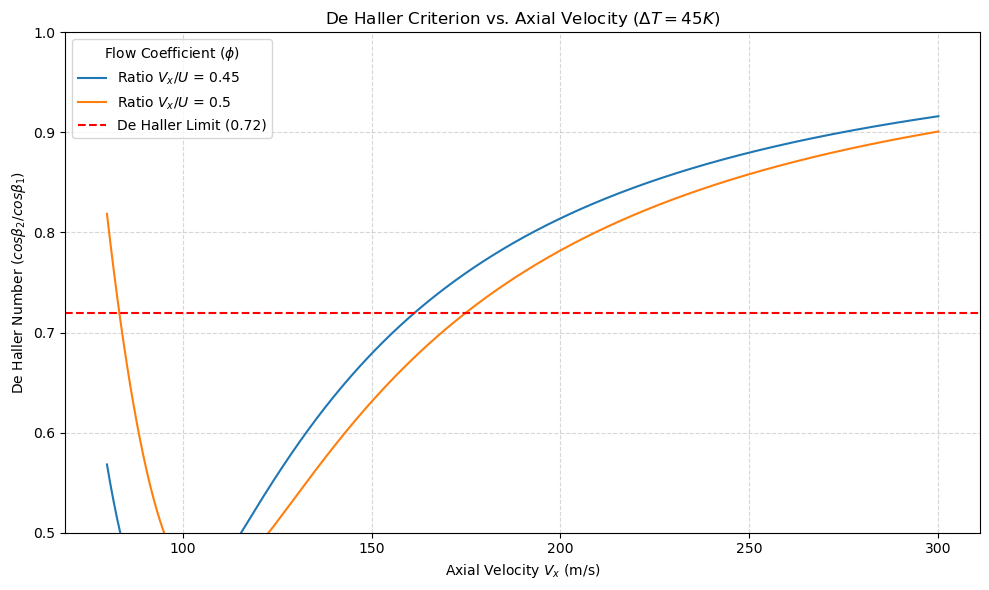

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
cp = 1005          # Specific heat [J/kgK]
delta_T = 45       # Fixed Temperature rise [K]
de_haller_limit = 0.72

# Define ranges
# Axial Velocity Vx on the x-axis
Vx = np.linspace(80, 300, 500)

# We want to test different Vx/U ratios (Flow Coefficients, phi)
# Common industrial ranges for axial compressors are roughly 0.4 to 0.9
phi_ratios = [0.45, 0.5]

plt.figure(figsize=(10, 6))

for phi in phi_ratios:
    # Since phi = Vx / U, then U = Vx / phi
    u = Vx / phi
    
    # Calculate angles based on your provided formulas
    tan_b1 = u / Vx
    tan_b2 = (u / Vx) - (cp * delta_T) / (u * Vx)
    
    # Calculate cos(beta) from tan(beta)
    cos_b1 = np.cos(np.arctan(tan_b1))
    cos_b2 = np.cos(np.arctan(tan_b2))
    
    # De Haller Number
    de_haller = cos_b1 / cos_b2
    
    plt.plot(Vx, de_haller, label=f"Ratio $V_x/U$ = {phi}")

# Add the limit line
plt.axhline(y=de_haller_limit, color='r', linestyle='--', label="De Haller Limit (0.72)")

# Formatting
plt.title(f"De Haller Criterion vs. Axial Velocity ($\Delta T = {delta_T}K$)")
plt.xlabel("Axial Velocity $V_x$ (m/s)")
plt.ylabel("De Haller Number ($cos\\beta_2 / cos\\beta_1$)")
plt.legend(title="Flow Coefficient ($\phi$)")
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.ylim(0.5, 1.0) # Focus on the relevant range

plt.tight_layout()
plt.show()

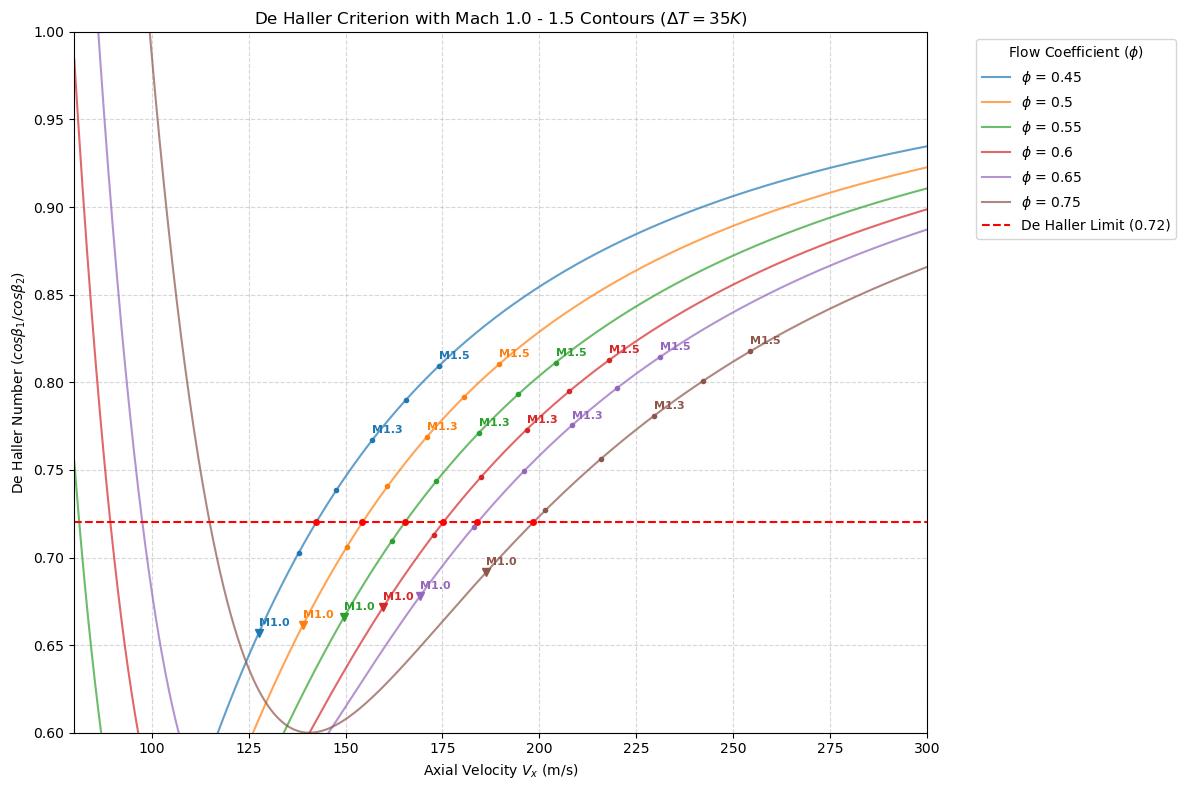

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# Constants
cp = 1005          # Specific heat [J/kgK]
delta_T = 35       # Fixed Temperature rise [K]
de_haller_limit = 0.72
gamma = 1.4
R = 287
T0 = 288.15

def calculate_de_haller(vx, phi):
    u = vx / phi
    tan_b1 = u / vx
    tan_b2 = (u / vx) - (cp * delta_T) / (u * vx)
    cos_b1 = 1 / np.sqrt(1 + tan_b1**2)
    cos_b2 = 1 / np.sqrt(1 + tan_b2**2)
    return cos_b1 / cos_b2

phi_ratios = [0.45, 0.5, 0.55, 0.6, 0.65, 0.75]
vx_range = np.linspace(80, 300, 1000)
mach_targets = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5]

plt.figure(figsize=(12, 8))

for phi in phi_ratios:
    # 1. Plot the main De Haller curve
    de_haller_vals = calculate_de_haller(vx_range, phi)
    line, = plt.plot(vx_range, de_haller_vals, label=f"$\phi$ = {phi}", alpha=0.7)
    color = line.get_color()

    # 2. Solve for the 0.72 crossing point (Stall Limit)
    func = lambda vx: calculate_de_haller(vx, phi) - de_haller_limit
    vx_cross = fsolve(func, 150)[0]
    plt.plot(vx_cross, de_haller_limit, 'ro', markersize=4)

    # 3. Calculate Mach Numbers along the curve
    # Total velocity W = sqrt(Vx^2 + U^2)
    v_total_sq = vx_range**2 * (1 + (1/phi)**2)
    T_static = T0 - v_total_sq / (2 * cp)
    a = np.sqrt(gamma * R * T_static)
    M_rel = np.sqrt(v_total_sq) / a

    # 4. Add Mach markers
    for M in mach_targets:
        idx = np.argmin(np.abs(M_rel - M))
        
        # Only plot if the Mach number is actually reached in our Vx range
        if abs(M_rel[idx] - M) < 0.05:
            marker = 'v' if M == 1.0 else '.' 
            plt.plot(vx_range[idx], de_haller_vals[idx], marker=marker, color=color)
            
            # Label only M=1.0 and M=1.5 to keep it clean, or every other one
            if M in [1.0, 1.3, 1.5]:
                plt.annotate(f'M{M}', (vx_range[idx], de_haller_vals[idx]), 
                             textcoords="offset points", xytext=(0, 5), 
                             fontsize=8, color=color, weight='bold')

# Formatting
plt.axhline(y=de_haller_limit, color='r', linestyle='--', label="De Haller Limit (0.72)")
plt.title(f"De Haller Criterion with Mach 1.0 - 1.5 Contours ($\Delta T = {delta_T}K$)")
plt.xlabel("Axial Velocity $V_x$ (m/s)")
plt.ylabel("De Haller Number ($cos\\beta_1 / cos\\beta_2$)")
plt.legend(title="Flow Coefficient ($\phi$)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.ylim(0.6, 1.0)
plt.xlim(80, 300)
plt.tight_layout()
plt.show()

In [17]:
import math


def compressor_inlet_iteration(
    mass_flow,
    T0=288.15,
    P0=98762,#101325,
    gamma=1.4,
    R=287,
    hub_tip_ratio=0.35,
    r_min=0.05,
    step=0.0005):

    #print(f"\n--- Compressor Inlet Design for Mass Flow: {mass_flow} kg/s ---")

    best_solution = None
    
    # search range: 0.05m to 0.5m
    r_search_range = [r_min + i*step for i in range(int((0.5 - r_min)/step))]

    min_M = 999
    max_M = 0
    
    cp = (gamma * R) / (gamma - 1) # specific heat capacity

    for r_tip in r_search_range:

        r_hub = hub_tip_ratio * r_tip
        r_mean = 0.5 * (r_tip + r_hub)
        blade_height = r_tip - r_hub
        area = math.pi * (r_tip**2 - r_hub**2)

        # interative density calculation
        # initial guess: use stagnation density, static density (rho) depends on velocity (Vx), but Vx depends on rho
        rho = P0 / (R * T0) 
        Vx = 0
        T_static = T0 
        
        valid_point = True  # flag to track if physics are violated

        # iterate to converge on static density
        for _ in range(10): 
            if rho <= 0: 
                valid_point = False
                break
                
            Vx = mass_flow / (rho * area)
            
            # static temperature
            T_static = T0 - (Vx**2) / (2 * cp)
            
            # if temp is negative, flow is impossible at this radius
            if T_static <= 0: 
                valid_point = False
                break 
            
            # static pressure (isentropic)
            P_static = P0 * (T_static / T0)**(gamma / (gamma - 1))
            
            # update density
            rho = P_static / (R * T_static)

        # skip this radius if physics were violated
        if not valid_point:
            continue

        # velocity triangles
        # coursework specifies Vx / U = 0.5 => U = 2 * Vx
        U = Vx/0.5

        # speed of sound (using static temp)
        a = math.sqrt(gamma * R * T_static)
        
        # relative velocity
        W = math.sqrt(U**2 + Vx**2)
        
        # relative Mach
        M_rel = W / a
        
        # rotational speed
        omega = U / r_mean
        RPM = omega * 60 / (2 * math.pi)

        # track extremes
        min_M = min(min_M, M_rel)
        max_M = max(max_M, M_rel)

        # optimization as coursework suggests M_rel approx 1.1
        current_diff = abs(M_rel - 1.1)
        
        if best_solution is None:
            best_diff = 999
        else:
            best_diff = abs(best_solution["M_rel"] - 1.1)

        # save if this is closer to 1.1 than previous best
        if current_diff < best_diff and (1.0 <= M_rel <= 1.2):
            best_solution = {
                "r_tip": r_tip,
                "r_hub": r_hub,
                "area": area,
                "RPM": RPM,
                "M_rel": M_rel,
                "blade_height": blade_height,
                "Vx": Vx,
                "U": U}

    print("\n--- Diagnostic Summary ---")
    if max_M == 0:
         print("No valid flow solutions found.")
    else:
        print(f"Range of Relative Machs found in sweep: {max_M:.2f} down to {min_M:.2f}")
    
    if best_solution:
        print("\n--- Optimal Compressor Inlet ---")
        print(f"Tip radius: {best_solution['r_tip']:.4f} m ({best_solution['r_tip']*1000:.1f} mm)")
        print(f"Hub radius: {best_solution['r_hub']:.4f} m ({best_solution['r_hub']*1000:.1f} mm)")
        print(f"Inlet Area: {best_solution['area']:.3f} m^2")
        print(f"Blade height: {best_solution['blade_height']*1000:.1f} mm")
        print(f"Relative Mach: {best_solution['M_rel']:.3f} (Target: 1.1)")
        print(f"Shaft speed: {best_solution['RPM']:.0f} RPM")
        print(f"Axial velocity Vx: {best_solution['Vx']:.2f} m/s")
        print(f"Blade speed U: {best_solution['U']:.2f} m/s")
        return best_solution
    else:
        print("\nNo feasible solution found.")
        #return NoneBlade speed U: 327.59 m/s


mass_flow = 12.5 
#fan_tip_radius = calculate_fan_diameter(mass_flow, altitude=0)
compressor_solution = compressor_inlet_iteration(mass_flow=mass_flow)

W_final = math.sqrt(compressor_solution['U']**2 + compressor_solution['Vx']**2)
print(f"Relative velocity W: {W_final:.2f} m/s")


--- Diagnostic Summary ---
Range of Relative Machs found in sweep: 6.22 down to 0.10

--- Optimal Compressor Inlet ---
Tip radius: 0.1615 m (161.5 mm)
Hub radius: 0.0565 m (56.5 mm)
Inlet Area: 0.072 m^2
Blade height: 105.0 mm
Relative Mach: 1.103 (Target: 1.1)
Shaft speed: 28722 RPM
Axial velocity Vx: 163.94 m/s
Blade speed U: 327.89 m/s
Relative velocity W: 366.59 m/s


In [2]:
import math

def calculate_compressor_stage_by_stage(mass_flow=12.5, T0_in=288.15,P0_in= 98762,P_out= 1975837, T_out = 730.49, Vx = 163.94,r_tip_inlet= 0.1615, eff_p = 0.9202):
        #mass_flow, T0_in, P0_in, P_out,T_out,  Vx, r_tip_inlet, eff_p=0.9202):
    R, gamma = 287, 1.4
    cp = (gamma * R) / (gamma - 1)
    PR_stage_max = 1.30
    dT_stage_max = 39.62
    MIN_HEIGHT = 0.010 # 10mm limit 

    # 1. Specific heat capacity
    cp = (gamma * R) / (gamma - 1)
    
    # 2. Calculate Static Temp and Pressure at the inlet
    T_static_in = T0_in - (Vx**2 / (2 * cp))
    P_static_in = P0_in * (T_static_in / T0_in)**(gamma / (gamma - 1))
    
    # 3. Calculate True Static Density
    rho_in = P_static_in / (R * T_static_in)

    area_in = mass_flow / (rho_in * Vx)
    #print(area_in)
    r_hub_in = math.sqrt(r_tip_inlet**2 - (area_in / math.pi))
    r_mean = (r_tip_inlet + r_hub_in) / 2
    
    current_T0, current_P0 = T0_in, P0_in
    m = (gamma-1)/(gamma * eff_p)


    target_P = P_out
    #print(target_P)
    target_T = T_out
    #print(target_T)


    #print(f"Constant Mean Radius: {r_mean:.4f} m")
    
    # start table
    print(f"{'Stage':<6} | {'P0 (kPa)':<10} | {'PR Stage':<8} | {'T0 (K)':<8} | {'dT (K)':<8}| {'Blade height (mm)':<12} | {'r_tip (mm)':<10} | {'Hub/Tip':<8} | {'r_hub (mm)':<10}")
    print("-" * 110)

    

    stage  =0
    blade_height_list = []
    blade_tip_list = []
    blade_hub_list = []
    #for stage in range(1, num_stages + 1):
    while current_P0 < target_P:

    #for stage in range(1, num_stages + 1):
        # update stagnation states
        stage += 1

        pr_per_stage = PR_stage_max
        
        TR_per_stage = pr_per_stage ** m
        dT_per_stage = current_T0*(TR_per_stage -1)
        

        if dT_per_stage > dT_stage_max:
            dT_per_stage = dT_stage_max
            TR_per_stage = (current_T0 + dT_per_stage) / current_T0
            pr_per_stage = TR_per_stage ** (1 / m)
        
        if pr_per_stage > PR_stage_max:
            pr_per_stage = PR_stage_max / current_P0
            TR_per_stage = pr_per_stage ** m
            dT_per_stage = current_T0 * (TR_per_stage - 1)

        if current_P0 * pr_per_stage > target_P:
            pr_per_stage = target_P / current_P0
            TR_per_stage = pr_per_stage ** m
            dT_per_stage = current_T0 * (TR_per_stage - 1)
            #limiting_factor = "Target Reached"


        current_P0 *= pr_per_stage
        current_T0 += dT_per_stage

        # calculate static properties 
        T_static = current_T0 - (Vx**2 / (2 * cp))
        P_static = current_P0 * (T_static / current_T0)**(gamma/(gamma-1))
        rho = P_static / (R * T_static)
        
        # calculate required area
        area = mass_flow / (rho * Vx)
        
        
        # constant mean radius geometry
        blade_height = area / (2 * math.pi * r_mean)
        
        # check against 10mm limit
        if blade_height < MIN_HEIGHT:
            blade_height = MIN_HEIGHT
        
        # derived radii
        r_tip = r_mean + (blade_height / 2)
        r_hub = r_mean - (blade_height / 2)

        r_tip = math.sqrt(r_hub_in**2 + area/(math.pi))
        blade_height = area / (2 * math.pi * r_mean)
        
        # check against 10mm limit
        #if blade_height < MIN_HEIGHT:
        #    blade_height = MIN_HEIGHT
        
        # derived radii
        r_tip = r_mean + (blade_height / 2)
        r_hub = r_mean - (blade_height / 2) #r_hub_in

        blade_height_list.append(blade_height)
        blade_hub_list.append(r_hub)
        blade_tip_list.append(r_tip)
        # table output
        print(f"{stage:<6} | {current_P0/1000:<10.1f} | {pr_per_stage:<8.3f} | {current_T0:<8.1f} | {(round(dT_per_stage,2)):<8}| {blade_height*1000:<17.2f} | {1000*r_tip:<10.2f} | {r_hub/r_tip:<9.3f}| {1000*r_hub:<10.2f}")
     
        if current_P0 > target_P:
            break
    

    return blade_height_list, blade_tip_list, blade_hub_list #  num_stages

calculate_compressor_stage_by_stage()

Stage  | P0 (kPa)   | PR Stage | T0 (K)   | dT (K)  | Blade height (mm) | r_tip (mm) | Hub/Tip  | r_hub (mm)
--------------------------------------------------------------------------------------------------------------
1      | 128.4      | 1.300    | 312.6    | 24.46   | 86.78             | 152.40     | 0.431    | 65.62     
2      | 166.9      | 1.300    | 339.1    | 26.53   | 71.79             | 144.90     | 0.505    | 73.12     
3      | 217.0      | 1.300    | 367.9    | 28.78   | 59.43             | 138.73     | 0.572    | 79.30     
4      | 282.1      | 1.300    | 399.1    | 31.23   | 49.23             | 133.63     | 0.632    | 84.39     
5      | 366.7      | 1.300    | 433.0    | 33.88   | 40.81             | 129.41     | 0.685    | 88.61     
6      | 476.7      | 1.300    | 469.8    | 36.75   | 33.84             | 125.93     | 0.731    | 92.09     
7      | 618.7      | 1.298    | 509.4    | 39.62   | 28.11             | 123.07     | 0.772    | 94.95     
8      | 787.5   

([0.08677817122594834,
  0.07178847254194692,
  0.05943019904168523,
  0.04923137592827037,
  0.04080707450196019,
  0.033842786714079746,
  0.028112733924060385,
  0.02368936781637429,
  0.020208178814977974,
  0.01742258649723675,
  0.015161146126216638,
  0.013301781250917834,
  0.01237069412619548],
 [0.15239951248476907,
  0.14490466314276834,
  0.13872552639263752,
  0.13362611483593007,
  0.12941396412277498,
  0.12593182022883476,
  0.12306679383382509,
  0.12085511077998204,
  0.11911451627928388,
  0.11772172012041326,
  0.11659099993490321,
  0.11566131749725381,
  0.11519577393489264],
 [0.06562134125882071,
  0.07311619060082143,
  0.07929532735095228,
  0.08439473890765971,
  0.0886068896208148,
  0.09208903351475502,
  0.0949540599097647,
  0.09716574296360775,
  0.09890633746430591,
  0.10029913362317652,
  0.10142985380868658,
  0.10235953624633598,
  0.10282507980869715])